# Classical Markowitz Portfolio Optimization

## 1. Introduction

In my class, discrete time financial mathematics, we were introduced to portfolio optimization. Mainly we covered the analytic solution described by Markowitz. The idea of this project is to first implement the analytic solution in code and compare with a purely numerical solution. This will be done using the integrated scipy.optimize. In the next notebooks, we will then look at what changes when portfolio decisions become discerete and if a variational quantum algorithm can solve this problem. The outlook is: can a learned model approximate solutions across varying portfolio parameters? But I am getting ahead of myself.

The idea of classical Markowitz Portfolio Optimizaiton is that risk is quantified by the variance of protfolio returns. We want  to find minimum variance portfolios (mvps), which are either efficient (more return than gmvp) or in-efficient (less return than gmvp), where the gmvp is the global minimum variance portfolio. This is written as:

$$ \min_{\pi \in \mathbb{R}^n} \frac{1}{2}\pi^T\Sigma\pi \qquad \textrm{s.t.} \qquad \pi^T m = m_p \quad \pi^T e=1$$

Where:

$$ \vec{\pi} \rightarrow \textrm{Portfolio Allocation} $$
$$ \vec{m} = \mathbb{E}[R] \rightarrow \textrm{Vector of expected asset return} $$
$$ \Sigma \rightarrow \textrm{Covariance Matrix} $$

So we are minimizing the variance, while keeping all of the assets invested and requiring a return of $m_p$. To solve this analytically, the lagrange multiplicator method is very useful. 

$$ L(\pi, \lambda, \mu) = \frac{1}{2}\pi^T\Sigma\pi -\lambda(\pi^Tm -m_p) -\mu(\pi^Te -1) $$
$$ \Rightarrow \nabla_{\pi}L = \Sigma\pi -\lambda m - \mu e \stackrel{!}{=} 0 $$

Taking that expression, we can multiply by $\Sigma^{-1}$ and use our two constraints ($\pi*m=m_p$ and $\pi*e=1$) to write this as a system of equations that we can solve.

$$ \begin{pmatrix} m^T\Sigma^{-1}m & m^T \Sigma^{-1} e \\ e^T\Sigma^{-1}m & e^T \Sigma^{-1} e \end{pmatrix} \begin{pmatrix} \lambda \\ \mu \end{pmatrix} = \begin{pmatrix} m_p \\ 1\end{pmatrix} $$

This notebook will be concise. First, will implement the analytic solution into code, then do the same but with a numerical method (SLSQP). We will compare these two, while highlighting the global mvp and see how the relationship is effected once we do not allow short selling (all values of $\pi$ must be positive).

## 2. Analytic Approach

I will model an mvp using completely synthetic values. These are the same values I will be using for the numerical approach. The only constraint is that the covariance matrix is positive semidefinit.

In [11]:
import numpy as np
import matplotlib.pyplot as plt

from portfolio_optimization.markowitz import mvp_analytic

In [ ]:
# number of assets in the portfolio
n_assets = 4
# expected asset returns
m = np.array([0.04, 0.07, 0.10, 0.13])

# vector of ones
e = np.ones(n_assets)

# expected portfolio return
m_p = 0.08

# the covariance matrix needs to be symmetric and positive semidefinit, construct sigma = A^T A ensures it is postive definite
A = np.array([[0.15, 0.02, 0.04, 0.01], 
            [0.02, 0.18, 0.03, 0.04],
            [0.04, 0.03, 0.22, 0.05],
            [0.01, 0.04, 0.05, 0.28]])

sigma = A.T @ A

analytic_solution = mvp_analytic(sigma, m, m_p)

print('The portfolio weight is π* =', analytic_solution )
print('The total Portfolio weight is', analytic_solution @ e)
print('The expected return is', analytic_solution @ m)
print('The portfolio variance is', analytic_solution @ sigma @ analytic_solution)

The portfolio weight is π* = [0.29616361 0.28849685 0.20118213 0.21415741]
The total Portfolio weight is 1.0
The expected return is 0.08000000000000002
THe portfolio variance is 0.02173584911340579


## 3. Numerical method

In this section we will try to replicate the results of the analytic method via numerical optimization using scipy.optimize. Sequential Least Squares Programming (SLSQP) is the method we will use, as it is an algorithm aimed at constrained optimization problems. It iteratively solves quadratic approximations, while accounting for constraints, making it suitable for our problem, as our optimization problem is quadratic itself.

In [13]:
from portfolio_optimization.markowitz import mvp_numerical
from portfolio_optimization.markowitz import gmvp

In [14]:
numerical_solution = mvp_numerical(sigma, m, m_p, allow_short = True)

print('The portfolio weight is π* =', numerical_solution.x)

The portfolio weight is π* = [0.29616361 0.28849686 0.20118211 0.21415742]


In [15]:
difference = np.linalg.norm(analytic_solution - numerical_solution.x)

print('The difference in the analytic and numerical approach is:', difference)

The difference in the analytic and numerical approach is: 1.8379055488951284e-08


In [ ]:
# create a space for possible m_ps from range 0.02 to 0.13
target_returns = np.linspace(0.02, 0.13, 100)

portfolio_variances_analytic =[]
portfolio_variances_numerical = []

# calculate the portfolio's variance for each m_p
for i in target_returns:
    pi_an = mvp_analytic(sigma, m, i)
    portfolio_variances_analytic.append(pi_an @ sigma @ pi_an)
    pi_num = mvp_numerical(sigma, m, i, allow_short = True)
    portfolio_variances_numerical.append(pi_num.x @ sigma @ pi_num.x)

# global minimum variance portfolio
pi_gmvp = gmvp(sigma)
m_gmvp = m @ pi_gmvp
var_gmvp = pi_gmvp.T @ sigma @ pi_gmvp

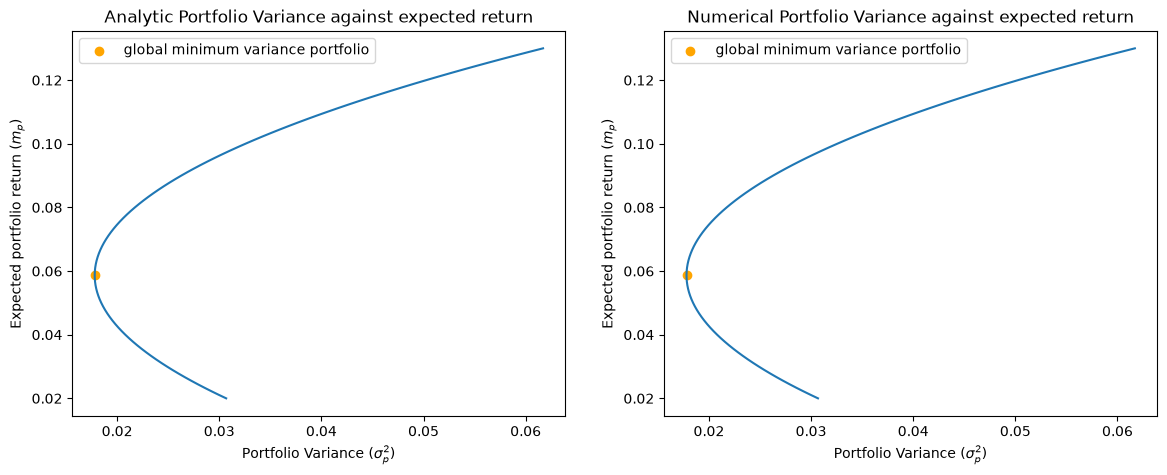

In [17]:
# plot return against portfolio variance
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(portfolio_variances_analytic, target_returns)
ax[0].scatter(var_gmvp, m_gmvp, label = 'global minimum variance portfolio', color = 'orange')
ax[0].set_title('Analytic Portfolio Variance against expected return')
ax[0].set_xlabel('Portfolio Variance ($\sigma_p^2$)')
ax[0].set_ylabel('Expected portfolio return ($m_p$)')
ax[0].legend()

ax[1].plot(portfolio_variances_numerical, target_returns)
ax[1].scatter(var_gmvp, m_gmvp, label = 'global minimum variance portfolio', color = 'orange')
ax[1].set_title('Numerical Portfolio Variance against expected return')
ax[1].set_xlabel('Portfolio Variance ($\sigma_p^2$)')
ax[1].set_ylabel('Expected portfolio return ($m_p$)')
ax[1].legend()

plt.show()

As we could already see from the difference, the anayltic solutiona nd numerical approxiamtion align up to order $10^{-8}$. The portfolios above the gmvp are efficient, whereas the ones below are called inefficient. This approach allowed for short-selling. We will now see what an extra constraint, i.e. no short selling, does to the graph.

### 3.1 No short selling constraint

The idea is, that in the function, mvp_numerical, we have inserted a boolean expression where you can decide if you allow or do not allow short selling. If no, there is a bound set and no entry in the returned list can be negative. If it is allowed, then there are no such bounds on the entries.

In [39]:
portfolio_variances_no_short = []
valid_returns = []

for m_p in target_returns:
    result = mvp_numerical(sigma, m, m_p, allow_short=False)

    if result.success:
        pi = result.x
        portfolio_variances_no_short.append(pi @ sigma @ pi)
        valid_returns.append(m_p)

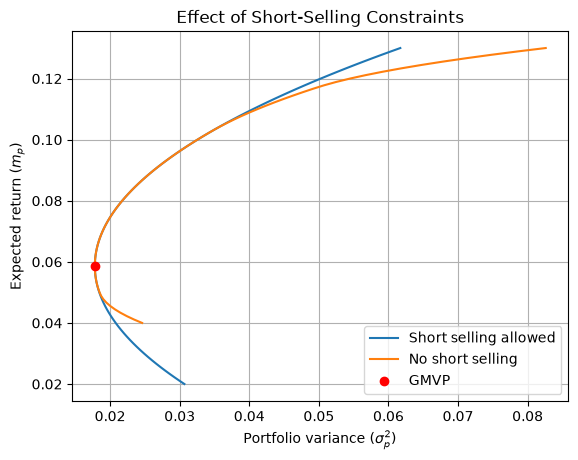

In [42]:
plt.plot(portfolio_variances_numerical, target_returns, label="Short selling allowed")
plt.plot(portfolio_variances_no_short, valid_returns, label="No short selling")
plt.scatter(var_gmvp, m_gmvp, color="red", label="GMVP", zorder=5)
plt.xlabel(r"Portfolio variance ($\sigma_p^2$)")
plt.ylabel(r"Expected return ($m_p$)")
plt.title("Effect of Short-Selling Constraints")
plt.legend()
plt.grid(True)
plt.show()

### 3.2 Effect of short-selling restraint

When allowing short selling, the set of allowed portfolios is determined only via the restraints. That means the set is:
$$ \mathcal{F} = \{\pi \in \mathbb{R}^n | \pi^Te=1, \pi^Tm= m_p\}$$
By adding the short-selling constraint, we have effectively added another constraint, so 
$$ \mathcal{F}_{\textrm{short}} \subseteq \mathcal{F}_{\textrm{no short}} $$
This then implies, that the variance of the no short protfolios (nsp) is bigger than or equal to those where shorts are allowed. This is readily visible in the graph we created.

Both regimes have the same global mvp. However, as all entries in the portfolio allocation are non-negative, this is not surprising. What we see, however, is that the higher the expected return, the bigger the difference in portfolio variance. This is a consequence of the nsp's need to buy more assets with higher return, which leads to mroe variance as it can get no capital from short selling. This also leads to a global cap on how much return the nsp can have, as it cannot endlessly finance itself through short selling.

In [43]:
target = 0.12

unrestricted = mvp_numerical(sigma, m, target, allow_short=True)
restricted = mvp_numerical(sigma, m, target, allow_short=False)

assert unrestricted.success and restricted.success

var_short = unrestricted.x @ sigma @ unrestricted.x
var_no_short = restricted.x @ sigma @ restricted.x

print("Variance penalty:", var_no_short - var_short)
print("Relative variance increase:", (var_no_short / var_short - 1) * 100, "%")

Variance penalty: 0.004206995815833982
Relative variance increase: 8.370520030422558 %


As an example, I have calculated the variance discrepancy at 12% return. The variance of the nsp is ostensibly larger than that of the sp.

